The Linnerud dataset contains physiological and exercise data for 20 individuals. It has three input features (age, weight, height) and three target variables (number of chin-ups, sit-ups, and jumps).

The goal is to develop and evaluate machine learning regression models and to predict physiological measurements (Weight, Waist, and Pulse) based on exercise performance (Chins, Situps, and Jumps). 

In [1]:
#import the necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_linnerud
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import r2_score, mean_squared_error


**Load and explore the Linnerud dataset**


In [2]:
# Load dataset
linnerud = load_linnerud()

# Create DataFrames
X = pd.DataFrame(linnerud.data,
                 columns=linnerud.feature_names)

y = pd.DataFrame(linnerud.target,
                 columns=linnerud.target_names)

# Combine for exploration
df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
print(df.head())


Dataset shape: (20, 6)
   Chins  Situps  Jumps  Weight  Waist  Pulse
0    5.0   162.0   60.0   191.0   36.0   50.0
1    2.0   110.0   60.0   189.0   37.0   52.0
2   12.0   101.0  101.0   193.0   38.0   58.0
3   12.0   105.0   37.0   162.0   35.0   62.0
4   13.0   155.0   58.0   189.0   35.0   46.0


In [3]:
#Split the data into training and testing sets before cleaning to avoid data leak

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training features: (16, 3)
Testing features: (4, 3)
Training targets: (16, 3)
Testing targets: (4, 3)


In [4]:
#Check for missing values

print("Missing values:")
print(df.isnull().sum())


Missing values:
Chins     0
Situps    0
Jumps     0
Weight    0
Waist     0
Pulse     0
dtype: int64


In [5]:
#descriptive statistic

print("Feature statistics:")
print(X.describe())

print("\nTarget statistics:")
print(y.describe())


Feature statistics:
           Chins      Situps      Jumps
count  20.000000   20.000000   20.00000
mean    9.450000  145.550000   70.30000
std     5.286278   62.566575   51.27747
min     1.000000   50.000000   25.00000
25%     4.750000  101.000000   39.50000
50%    11.500000  122.500000   54.00000
75%    13.250000  210.000000   85.25000
max    17.000000  251.000000  250.00000

Target statistics:
           Weight      Waist      Pulse
count   20.000000  20.000000  20.000000
mean   178.600000  35.400000  56.100000
std     24.690505   3.201973   7.210373
min    138.000000  31.000000  46.000000
25%    160.750000  33.000000  51.500000
50%    176.000000  35.000000  55.000000
75%    191.500000  37.000000  60.500000
max    247.000000  46.000000  74.000000


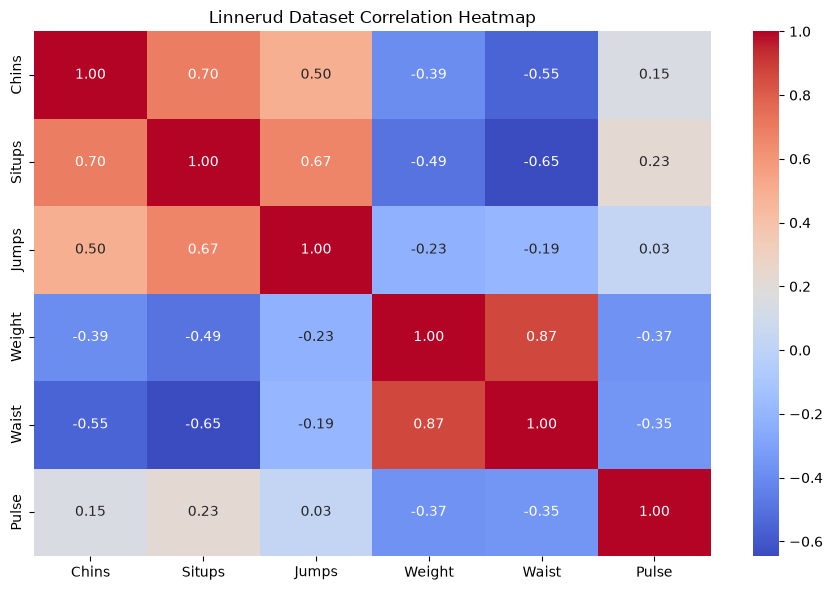

In [6]:
#Correlation heatmap

plt.figure(figsize=(9, 6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Linnerud Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()


The correlation heatmap shows the relationships between the three exercise features (Chins, Situps, and Jumps) and the three target variables (Weight, Waist, and Pulse).1 means a stong positive relationship and -1 means a stong negative relationship.

Weight and Waist of 0.87 indicates a strong positive correlation meaning that individuals with higher body weight tend to have larger waist measurements.
Chins and Situps of 0.70 indicates that individuals who perform more chin-ups also tend to perform more sit-ups. showing a positive relationship

Chins and Waist of -0.55 indicates that individuals who perform more chin-ups tend to have smaller waist measurements.

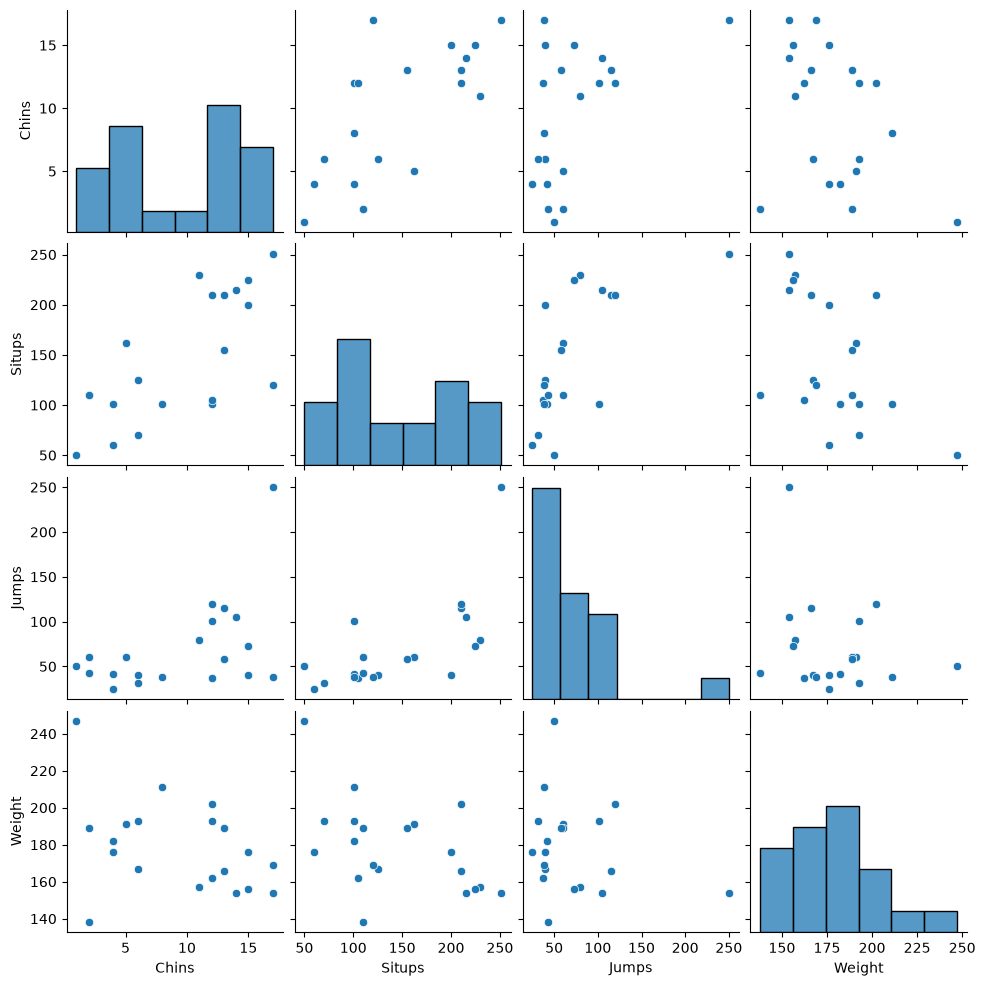

In [7]:
#Create a pairplot
sns.pairplot(
    df[["Chins", "Situps", "Jumps", "Weight"]],
    diag_kind="hist"
)

plt.show()


**Build a Linear Regression Model**

In [8]:
# Initialize model
lr_model = LinearRegression()

# Train model
lr_model.fit(X_train, y_train)

# Predict on test data
y_pred = lr_model.predict(X_test)

# Display predictions
predictions = pd.DataFrame(
    y_pred,
    columns=y.columns,
    index=y_test.index
)

print(predictions)


        Weight      Waist      Pulse
0   166.299446  34.349313  61.692687
17  149.165443  31.140784  64.132980
15  159.626702  33.151725  59.782455
1   181.509420  37.106506  58.293805


The predicted weights range from approximately 149.17 to 181.51
The predicted waist measurements range from 31.14 to 37.11.
The predicted pulse rates range from approximately 58.29 to 64.13 beats per minute

**Evaluate the Linear Regression Model**

In [9]:
results = []

for i, target in enumerate(y.columns):
    r2 = r2_score(y_test.iloc[:, i], y_pred[:, i])

    rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            y_pred[:, i]
        )
    )

    results.append([target, r2, rmse])

results_df = pd.DataFrame(
    results,
    columns=["Target", "R2 Score", "RMSE"]
)

print(results_df)


   Target  R2 Score       RMSE
0  Weight -1.243257  25.115249
1   Waist -0.075505   2.137965
2   Pulse -2.732473   9.061700


The negative R² indicates that the model performs worse than simply predicting the mean weight of the test observations.The RMSE of 25.12 indicates substantial prediction errors in weight measurements.

In [17]:
#Compare Actual vs. Predicted Values
comparison = pd.DataFrame(index=y_test.index)

for i, target in enumerate(y.columns):
    comparison[f"Actual {target}"] = y_test[target]
    comparison[f"Predicted {target}"] = y_pred[:, i]

print(comparison.round(2))


    Actual Weight  Predicted Weight  Actual Waist  Predicted Waist  \
0           191.0            166.30          36.0            34.35   
17          157.0            149.17          32.0            31.14   
15          202.0            159.63          37.0            33.15   
1           189.0            181.51          37.0            37.11   

    Actual Pulse  Predicted Pulse  
0           50.0            61.69  
17          52.0            64.13  
15          62.0            59.78  
1           52.0            58.29  


Based on the output, the model underestimated the weight of all four individuals.
The Waist predictions were relatively close to the actual values compared with the other targets in their respective units and for pulse evaluation, the model overestimated Pulse for three individuals and underestimated it for one.

All this shows how poorly the model performed as seen in teh result of the R2 Score

**Visualize actual vs. predicted values**

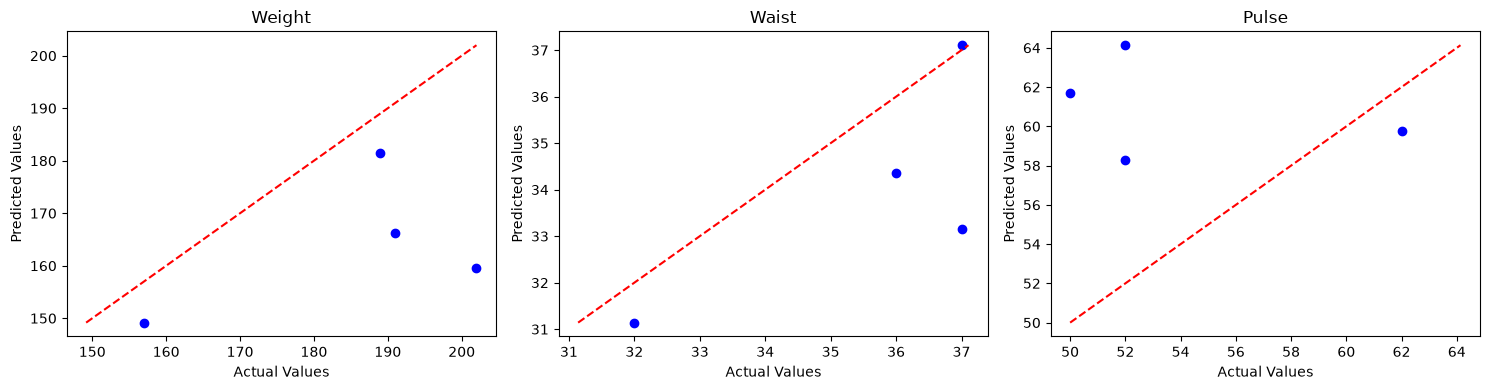

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, target in enumerate(y.columns):
    actual = y_test.iloc[:, i]
    predicted = y_pred[:, i]

    axes[i].scatter(actual, predicted, color="blue")

    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())

    axes[i].plot(
        [low, high],
        [low, high],
        "r--"
    )

    axes[i].set_title(target)
    axes[i].set_xlabel("Actual Values")
    axes[i].set_ylabel("Predicted Values")

plt.tight_layout()
plt.show()


All points are far from teh line indicating a huge error in failing to predict actual.

**Make predictions on new data**

In [11]:
# Select one test observation
new_data = X_test.iloc[[0]]

# Make prediction
new_prediction = lr_model.predict(new_data)

print("Input data:")
print(new_data)

print("\nPredicted values:")
print(pd.DataFrame(
    new_prediction,
    columns=y.columns
))

print("\nActual values:")
print(y_test.iloc[[0]])


Input data:
   Chins  Situps  Jumps
0    5.0   162.0   60.0

Predicted values:
       Weight      Waist      Pulse
0  166.299446  34.349313  61.692687

Actual values:
   Weight  Waist  Pulse
0   191.0   36.0   50.0


Even with teh new dataset, the model still did not predict the actual. The waist predicted was close to the actual but still compared with the other targets

**Improve the Model Using Feature Scaling**

In [12]:
# Create scaler
scaler = StandardScaler()

# Scale training data
X_train_scaled = scaler.fit_transform(X_train)

# Scale test data
X_test_scaled = scaler.transform(X_test)

# Train model
scaled_model = LinearRegression()
scaled_model.fit(X_train_scaled, y_train)

# Predict
y_pred_scaled = scaled_model.predict(X_test_scaled)

# Evaluate
for i, target in enumerate(y.columns):
    r2 = r2_score(
        y_test.iloc[:, i],
        y_pred_scaled[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            y_pred_scaled[:, i]
        )
    )

    print(f"{target}: R2={r2:.3f}, RMSE={rmse:.3f}")


Weight: R2=-1.243, RMSE=25.115
Waist: R2=-0.076, RMSE=2.138
Pulse: R2=-2.732, RMSE=9.062


Weight with R² of -1.243, and RMSE of 25.115 indicates that the model continues to perform poorly in predicting Weight.
A negative R² indicates that predictions are worse than using the test-set mean as a baseline and that scaling did not reduce prediction errors.

**Improve the Model Using Feature Engineering**

In [13]:
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

# Train
poly_model.fit(X_train, y_train)

# Predict
y_pred_poly = poly_model.predict(X_test)

# Evaluate
for i, target in enumerate(y.columns):
    r2 = r2_score(
        y_test.iloc[:, i],
        y_pred_poly[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            y_pred_poly[:, i]
        )
    )

    print(f"{target}: R2={r2:.3f}, RMSE={rmse:.3f}")


Weight: R2=-11.070, RMSE=58.258
Waist: R2=-7.085, RMSE=5.862
Pulse: R2=-29.421, RMSE=25.870


Weight with R² score of -11.070, and RMSE of 58.258 indicates that R² decreased from -1.243 (standard scaling) to -11.070 (polinomail), indicating significantly worse predictive performance. Also, RMSE increased from 25.115 to 58.258, meaning the prediction errors became much larger. Therefore, the polynomial model did not capture a relationship that generalized well to the test data.

**Build a Lasso Regression Model**

In [14]:
# Create Lasso model with scaling
lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1.0, max_iter=10000)
)

# Train model
lasso_model.fit(X_train, y_train)

# Predict
y_pred_lasso = lasso_model.predict(X_test)

# Evaluate
for i, target in enumerate(y.columns):
    r2 = r2_score(
        y_test.iloc[:, i],
        y_pred_lasso[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_test.iloc[:, i],
            y_pred_lasso[:, i]
        )
    )

    print(f"{target}: R2={r2:.3f}, RMSE={rmse:.3f}")


Weight: R2=-0.845, RMSE=22.780
Waist: R2=0.159, RMSE=1.890
Pulse: R2=-0.380, RMSE=5.510


After applying Lasso Regression, the model's performance improved across all three target variables (Weight, Waist, and Pulse) compared with standard scaling and polynomial.

R² improved from -1.243 to -0.845 and RMSE decreased from 25.115 to 22.780, indicating smaller prediction errors. However, the negative R² still indicates that the model performs worse than the test-set mean baseline.

**Compare All Models**

In [15]:
models_predictions = {
    "Linear Regression": y_pred,
    "Scaled Linear Regression": y_pred_scaled,
    "Polynomial Regression": y_pred_poly,
    "Lasso Regression": y_pred_lasso
}

comparison = []

for model_name, preds in models_predictions.items():
    for i, target in enumerate(y.columns):
        r2 = r2_score(y_test.iloc[:, i], preds[:, i])
        rmse = np.sqrt(
            mean_squared_error(y_test.iloc[:, i], preds[:, i])
        )

        comparison.append([
            model_name,
            target,
            r2,
            rmse
        ])

comparison_df = pd.DataFrame(
    comparison,
    columns=["Model", "Target", "R2", "RMSE"]
)

print(comparison_df.round(3))


                       Model  Target      R2    RMSE
0          Linear Regression  Weight  -1.243  25.115
1          Linear Regression   Waist  -0.076   2.138
2          Linear Regression   Pulse  -2.732   9.062
3   Scaled Linear Regression  Weight  -1.243  25.115
4   Scaled Linear Regression   Waist  -0.076   2.138
5   Scaled Linear Regression   Pulse  -2.732   9.062
6      Polynomial Regression  Weight -11.070  58.258
7      Polynomial Regression   Waist  -7.085   5.862
8      Polynomial Regression   Pulse -29.421  25.870
9           Lasso Regression  Weight  -0.845  22.780
10          Lasso Regression   Waist   0.159   1.890
11          Lasso Regression   Pulse  -0.380   5.510


**Visualize the model comparison**

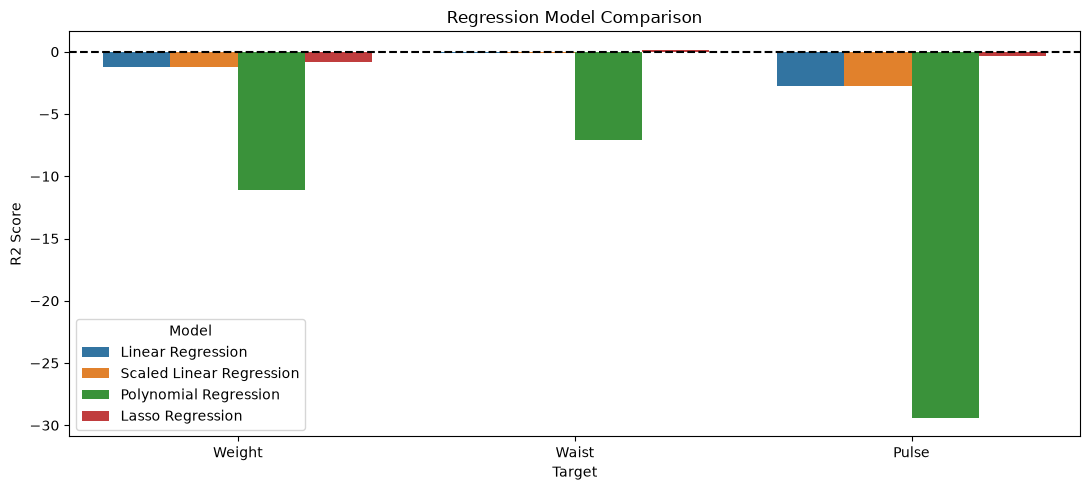

In [16]:
plt.figure(figsize=(11, 5))

sns.barplot(
    data=comparison_df,
    x="Target",
    y="R2",
    hue="Model"
)

plt.title("Regression Model Comparison")
plt.ylabel("R2 Score")
plt.axhline(0, color="black", linestyle="--")
plt.tight_layout()
plt.show()


The results show that Lasso Regression performed best across all three target variables (Weight, Waist, and Pulse), while Polynomial Regression performed the worst.
